In [1]:
!wget https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1

--2026-10-08 09:37:50--  https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 188.184.98.114, 137.138.52.235, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 208468073 (199M) [application/octet-stream]
Saving to: ‘Audio_Speech_Actors_01-24.zip?download=1’

Audio_Speech_Actors 100%[===================>] 198.81M  1.56MB/s    in 2m 34s  

2026-10-08 09:40:25 (1.29 MB/s) - ‘Audio_Speech_Actors_01-24.zip?download=1’ saved [208468073/208468073]



In [2]:
!unzip "/content/Audio_Speech_Actors_01-24.zip?download=1" -d "/content/Audio_Speech_Actors_01-24"

Archive:  /content/Audio_Speech_Actors_01-24.zip?download=1
   creating: /content/Audio_Speech_Actors_01-24/Actor_01/
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-01-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-02-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-01-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-02-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-01-01-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-01-02-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-02-01-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-02-02-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-02-01-01-01.wav  
  inflating: /content/Audio_Speech_Actors_01-24/Actor_01/03-01-02-02-01-02-01.wav  
  inflating: /content/Audio_Speech_Actors_

# Importing required libraries

In [3]:
import os
import random
import numpy as np
import librosa
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import Wav2Vec2Model
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

In [31]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

#Data Preprocessing

In [32]:
EMOTION_MAP = {
    1:"neutral",
    2:"calm",
    3:"happy",
    4:"sad",
    5:"angry",
    6:"fearful",
    7:"disgust",
    8:"surprised",

}
LABELS = list(EMOTION_MAP.values())
label2id = {label: idx for idx, label in enumerate(LABELS)}
id2label = {idx : label for idx, label in enumerate(LABELS)}

In [33]:
print(LABELS)
print(label2id)
print(id2label)

['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
{'neutral': 0, 'calm': 1, 'happy': 2, 'sad': 3, 'angry': 4, 'fearful': 5, 'disgust': 6, 'surprised': 7}
{0: 'neutral', 1: 'calm', 2: 'happy', 3: 'sad', 4: 'angry', 5: 'fearful', 6: 'disgust', 7: 'surprised'}


In [6]:
def ravdess_parse(file_name):
  #03-01-01-01-01-01-01.wav
  parts = file_name.replace(".wav","").split('-')
  emotion_code = int(parts[2])
  return emotion_code

def load_dataset(data_path = ""):
  items = []
  for root, dirs, files in os.walk(data_path):
    for file in files:
      emotion_code = ravdess_parse(file)
      label_id = label2id[EMOTION_MAP[emotion_code]]
      full_path = os.path.join(root, file)
      items.append((full_path, label_id))
  return items



In [7]:
all_items = load_dataset(data_path = "/content/Audio_Speech_Actors_01-24")

In [8]:
print(len(all_items))

1440


In [9]:
random.shuffle(all_items)

total_samples = len(all_items)
val_size = int(0.15 * total_samples)
test_size = int(0.15 * total_samples)

test_items = all_items[:test_size]
val_items = all_items[test_size:test_size+val_size]
train_items = all_items[test_size+val_size:]

print("Train Samples : ", len(train_items))
print("Val Samples: ", len(val_items))
print("Test Samples: ", len(test_items))

Train Samples :  1008
Val Samples:  216
Test Samples:  216


In [10]:
TARGET_SR = 16000
MAX_SECONDS = 4.0
MAX_LEN = int(TARGET_SR * MAX_SECONDS)
BATCH_SIZE = 64

In [11]:
class EmotionDataset(Dataset):
    def __init__(self, file_paths, labels, augment=False):
        self.file_paths = file_paths
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        audio_path = self.file_paths[idx]
        label = self.labels[idx]
        audio = self.load_audio(audio_path, augment=self.augment)

        return torch.FloatTensor(audio), torch.LongTensor([label])[0]

    def load_audio(self, path, augment=False):
        y, sr = librosa.load(path, sr=TARGET_SR, mono=True)
        if augment:
            if np.random.random() < 0.3:
                rate = np.random.uniform(0.9, 1.1)
                y = librosa.effects.time_stretch(y, rate=rate)

            if np.random.random() < 0.3:
                n_steps = np.random.randint(-2, 3)
                y = librosa.effects.pitch_shift(y, sr=TARGET_SR, n_steps=n_steps)

            if np.random.random() < 0.3:
                noise = np.random.normal(0, 0.005, y.shape)
                y = y + noise

        y = librosa.util.normalize(y)
        if len(y) > MAX_LEN:
            y = y[:MAX_LEN]
        else:
            y = np.pad(y, (0, MAX_LEN - len(y)), mode='constant')

        return y.astype(np.float32)

In [12]:
train_paths = [item[0] for item in train_items]
train_labels = [item[1] for item in train_items]
test_paths = [item[0] for item in test_items]
test_labels = [item[1] for item in test_items]
val_paths = [item[0] for item in val_items]
val_labels = [item[1] for item in val_items]

In [13]:
train_dataset = EmotionDataset(train_paths, train_labels, augment=True)
test_dataset = EmotionDataset(test_paths, test_labels)
val_dataset = EmotionDataset(val_paths, val_labels)

In [14]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers =2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,shuffle=False, num_workers =2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE,shuffle=False, num_workers =2)

#Model Making

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [16]:
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

In [34]:
NUM_CLASSES = len(LABELS)

In [18]:
class EmotionClassifier(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, freeze_backbone=True):
        super(EmotionClassifier, self).__init__()
        self.backbone = Wav2Vec2Model.from_pretrained("superb/wav2vec2-base-superb-er")
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
        hidden_size = self.backbone.config.hidden_size
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, audio):
        with torch.no_grad() if not self.training or self._is_backbone_frozen() else torch.enable_grad():
            outputs = self.backbone(audio)
            hidden_states = outputs.last_hidden_state

        mean_pool = torch.mean(hidden_states, dim=1)
        max_pool = torch.max(hidden_states, dim=1)[0]
        pooled = torch.cat([mean_pool, max_pool], dim=1)
        logits = self.classifier(pooled)
        return logits

    def _is_backbone_frozen(self):
        return not next(self.backbone.parameters()).requires_grad

    def unfreeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = True
        print("Backbone unfrozen for fine-tuning")


In [19]:
NUM_EPOCHS_PHASE1 = 30
NUM_EPOCHS_PHASE2 = 20
LEARNING_RATE_PHASE1 = 3e-4
LEARNING_RATE_PHASE2 = 1e-5

In [20]:
model = EmotionClassifier(num_classes=NUM_CLASSES, freeze_backbone=True).to(device)

config.json:   0%|          | 0.00/2.15k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: superb/wav2vec2-base-superb-er
Key               | Status     |  | 
------------------+------------+--+-
layer_weights     | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 
projector.weight  | UNEXPECTED |  | 
projector.bias    | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [21]:
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Total parameters: 95,325,704
Trainable parameters: 953,992


In [22]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for audio, labels in tqdm(dataloader, desc="Training"):
        audio, labels = audio.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(audio)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(dataloader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for audio, labels in tqdm(dataloader, desc="Validation"):
            audio, labels = audio.to(device), labels.to(device)

            outputs = model(audio)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(dataloader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# Phase 1 : Training with the frozen backbone

In [23]:
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE_PHASE1)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3
)

best_val_acc = 0
patience_counter = 0
patience = 8

In [24]:
for epoch in range(NUM_EPOCHS_PHASE1):
  print(f"Epoch {epoch+1}/{NUM_EPOCHS_PHASE1}")
  train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
  val_loss, val_acc = validate(model, val_loader, criterion, device)
  print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
  print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

  scheduler.step(val_acc)
  ##early stoping
  if val_acc > best_val_acc:
    best_val_acc = val_acc
    patience_counter = 0
    torch.save(model.state_dict(), "best_model_phase1.pth")

  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping triggered")
      break

Epoch 1/30


Training:   0%|          | 0/16 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Validation: 100%|██████████| 4/4 [00:07<00:00,  1.80s/it]


...

Train Loss: 1.3162, Train Acc: 51.69%
Val Loss: 1.2858, Val Acc: 53.24%
Epoch 29/30


Validation: 100%|██████████| 4/4 [00:06<00:00,  1.64s/it]


Train Loss: 1.3195, Train Acc: 49.40%
Val Loss: 1.2873, Val Acc: 57.87%
Epoch 30/30


Validation: 100%|██████████| 4/4 [00:07<00:00,  1.75s/it]

Train Loss: 1.3333, Train Acc: 49.60%
Val Loss: 1.2863, Val Acc: 53.70%


In [26]:
best_val_acc

57.870370370370374

In [35]:
model.load_state_dict(torch.load("/content/best_model_phase1.pth"))

<All keys matched successfully>

#Phase 2 Training

In [36]:
model.unfreeze_backbone()

Backbone unfrozen for fine-tuning


In [37]:
optimizer = torch.optim.Adam(model.parameters(),lr=LEARNING_RATE_PHASE2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'max', factor=0.5, patience = 4)
best_val_acc = 0
patience_counter = 0
patience = 10

In [38]:
for epoch in range(NUM_EPOCHS_PHASE2):
  print(f"Epoch {epoch+1}/{NUM_EPOCHS_PHASE1}")
  train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
  val_loss, val_acc = validate(model, val_loader, criterion, device)
  print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
  print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

  scheduler.step(val_acc)
  ##early stoping
  if val_acc > best_val_acc:
    best_val_acc = val_acc
    patience_counter = 0
    torch.save(model.state_dict(), "best_model_phase2.pth")

  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping triggered")
      break

Epoch 1/30


Validation: 100%|██████████| 4/4 [00:07<00:00,  1.94s/it]


Train Loss: 1.3492, Train Acc: 48.71%
Val Loss: 1.1449, Val Acc: 59.26%
Epoch 2/30


Validation: 100%|██████████| 4/4 [00:07<00:00,  1.85s/it]


Train Loss: 1.2708, Train Acc: 53.17%
Val Loss: 1.0952, Val Acc: 61.57%
Epoch 3/30


...

Train Loss: 0.9074, Train Acc: 69.64%
Val Loss: 0.7161, Val Acc: 77.78%
Epoch 19/30


Validation: 100%|██████████| 4/4 [00:07<00:00,  1.92s/it]


Train Loss: 0.9143, Train Acc: 69.35%
Val Loss: 0.6958, Val Acc: 75.46%
Epoch 20/30


Validation: 100%|██████████| 4/4 [00:06<00:00,  1.70s/it]

Train Loss: 0.9587, Train Acc: 67.46%
Val Loss: 0.6917, Val Acc: 77.78%


In [39]:
best_val_acc

77.77777777777777

Model Testing

In [46]:
# Load the best Phase 2 model
model.load_state_dict(
    torch.load("/content/best_model_phase2.pth", map_location=device)
)

# Set model to evaluation mode
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for audio, labels in tqdm(test_loader, desc="Testing"):
        audio = audio.to(device)
        outputs = model(audio)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

test_acc = 100 * np.sum(
    np.array(all_preds) == np.array(all_labels)
) / len(all_labels)

print(f"Test Accuracy: {test_acc:.2f}%")

Testing: 100%|██████████| 4/4 [00:08<00:00,  2.06s/it]

Test Accuracy: 78.70%


In [47]:
torch.save(model.state_dict(), "final_model_ravdess_sp_emotion.pth")

In [48]:
!mkdir -p /content/drive/MyDrive/Speech_Emotion_Recognition/

Confusion Matrics

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

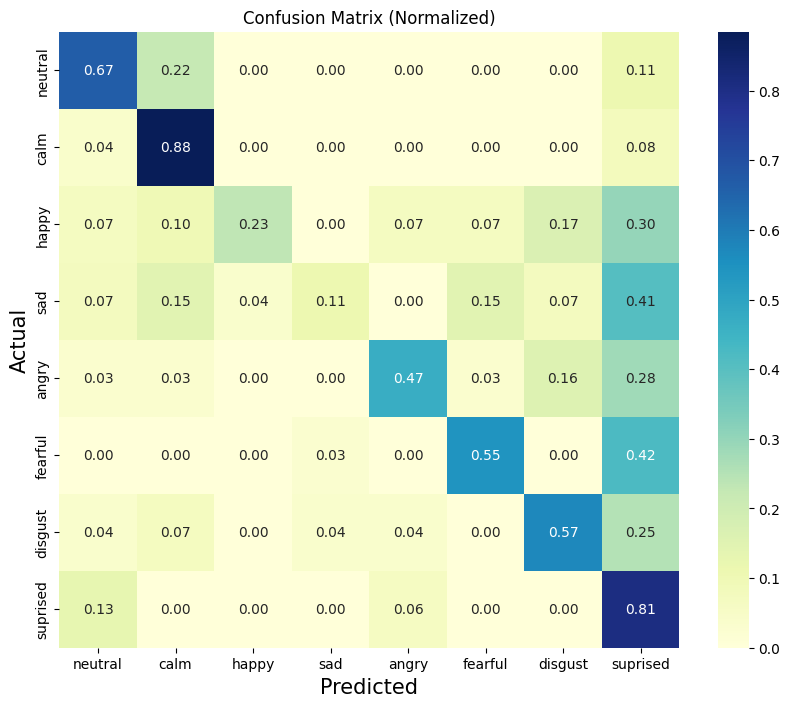

In [30]:
cm = confusion_matrix(y_true=all_labels, y_pred=all_preds)
cm = np.array(cm)

cmn = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cmn,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=LABELS,
    yticklabels=LABELS,
    ax=ax
)

ax.set_title("Confusion Matrix (Normalized)")
ax.set_ylabel("Actual", fontsize=15)
ax.set_xlabel("Predicted", fontsize=15)
plt.show()